In [19]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully!")
print("Titanic EDA project is ready.")

Libraries imported successfully!
Titanic EDA project is ready.


In [ ]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)
df.to_csv(DATA_DIR / "titanic.csv", index=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()

display(df.describe())

print(df.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [4]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (missing_values / len(df) * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)


,Missing Values,Percentage
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


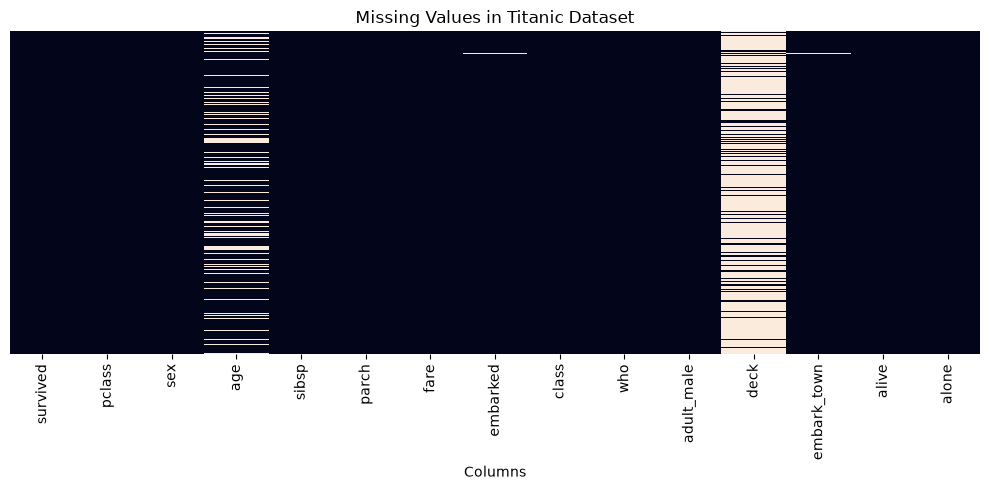

In [5]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()

In [6]:
df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])
df["fare"] = df["fare"].fillna(df["fare"].median())
df["deck"] = df["deck"].fillna("Unknown")

df["alone"] = df["alone"].fillna(False)

print("Missing values handled successfully!")

display(df.isnull().sum())

Missing values handled successfully!


survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64

In [7]:
df.to_csv(OUTPUT_DIR / "titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [8]:
survival_counts = df["survived"].value_counts().sort_index()

print("Passenger Survival Counts")
print("Did not survive:", survival_counts.get(0, 0))
print("Survived:", survival_counts.get(1, 0))

survival_rate = df["survived"].mean() * 100

print(f"\nOverall Survival Rate: {survival_rate:.2f}%")

Passenger Survival Counts
Did not survive: 549
Survived: 342

Overall Survival Rate: 38.38%


In [9]:
gender_survival = df.groupby("sex")["survived"].mean() * 100

display(gender_survival.round(2).reset_index(name="Survival Rate (%)"))

,sex,Survival Rate (%)
0,female,74.20
1,male,18.89


In [10]:
class_survival = df.groupby("pclass")["survived"].mean() * 100

display(class_survival.round(2).reset_index(name="Survival Rate (%)"))

,pclass,Survival Rate (%)
0,1,62.96
1,2,47.28
2,3,24.24


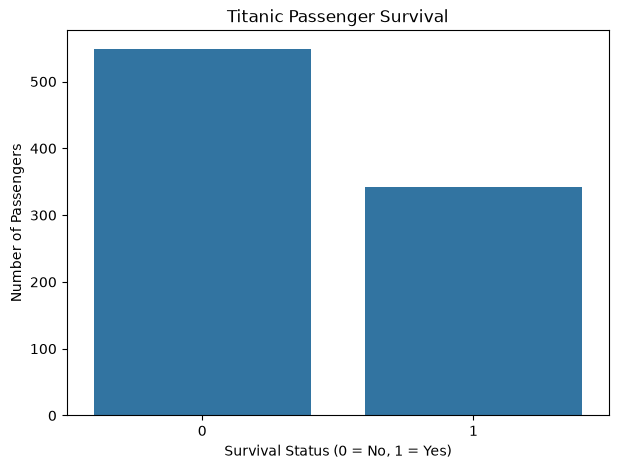

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="survived")

plt.title("Titanic Passenger Survival")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.savefig(OUTPUT_DIR / "survival_chart.png", dpi=150)
plt.show()

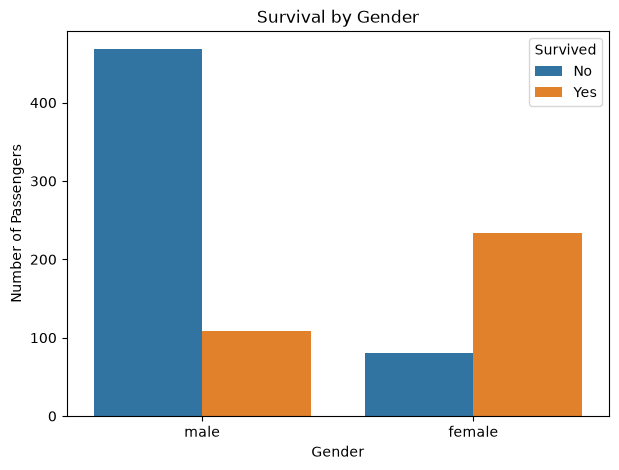

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex", hue="survived")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(title="Survived", labels=["No", "Yes"])
plt.savefig(OUTPUT_DIR / "survival_by_gender.png", dpi=150)
plt.show()

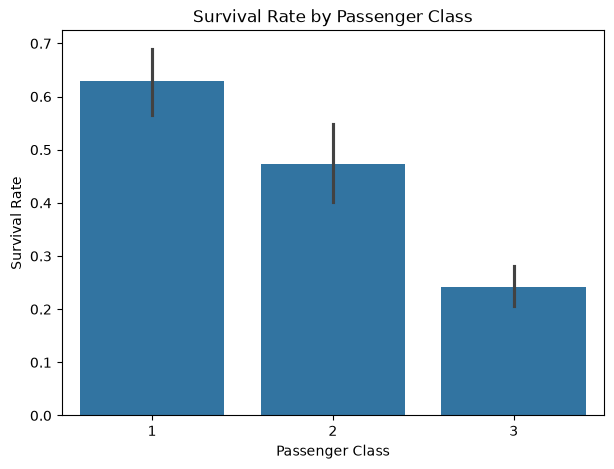

In [13]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df, x="pclass", y="survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.savefig(OUTPUT_DIR / "survival_by_class.png", dpi=150)
plt.show()

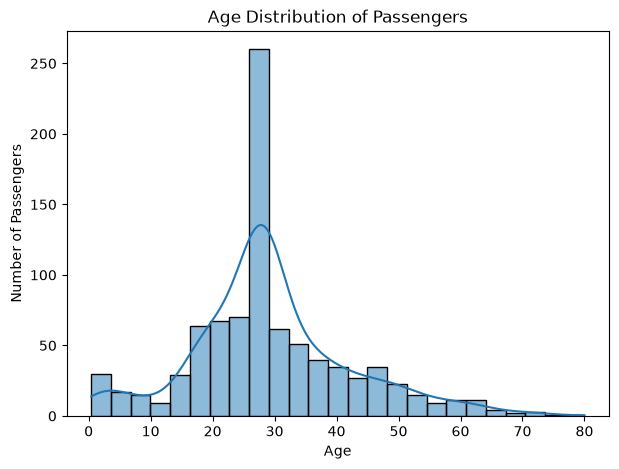

In [14]:
plt.figure(figsize=(7, 5))

sns.histplot(data=df, x="age", bins=25, kde=True)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.savefig(OUTPUT_DIR / "age_distribution.png", dpi=150)
plt.show()

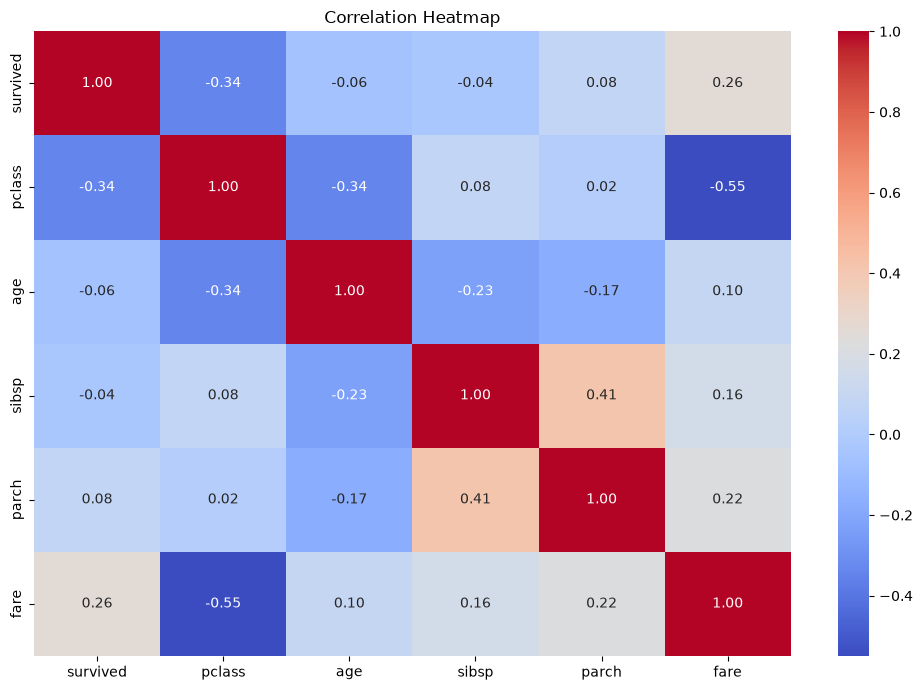

In [15]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

In [16]:
print("Average passenger age:", round(df["age"].mean(), 2))
print("Average ticket fare:", round(df["fare"].mean(), 2))

print("\nSurvival rate by age group:")

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

display(
    (df.groupby("age_group", observed=False)["survived"].mean() * 100)
    .round(2)
    .reset_index(name="Survival Rate (%)")
)

Average passenger age: 29.36
Average ticket fare: 32.2

Survival rate by age group:


,age_group,Survival Rate (%)
0,Child,57.97
1,Teenager,42.86
2,Young Adult,35.33
3,Adult,40.00
4,Senior,22.73


In [17]:
summary = f"""
TITANIC DATASET ANALYSIS SUMMARY

Total passengers: {len(df)}
Total columns: {len(df.columns)}
Overall survival rate: {df['survived'].mean() * 100:.2f}%
Average passenger age: {df['age'].mean():.2f}
Average ticket fare: {df['fare'].mean():.2f}

Survival rate by gender (%):
{(df.groupby('sex')['survived'].mean() * 100).round(2).to_string()}

Survival rate by passenger class (%):
{(df.groupby('pclass')['survived'].mean() * 100).round(2).to_string()}
"""

(OUTPUT_DIR / "analysis_summary.txt").write_text(
    summary,
    encoding="utf-8"
)

print("Analysis summary saved successfully!")

Analysis summary saved successfully!
